# Question D: When does citation impact emerge, and which papers become “high hitters”?

**Journal:** *Financial Services Review* (FSR)  
**Citation window:** through 2025, the last complete calendar year

This analysis addresses two related questions about research impact in *Financial Services Review*. The first asks **how long it typically takes for a paper to reach its highest observed annual citation count**. The second asks **which observable paper characteristics are associated with becoming a highly cited paper**.

Taken together, the two parts separate **timing** from **predictability**: Part 1 shows when impact tends to become visible, while Part 2 examines whether high-impact papers can be distinguished from the rest using information available in the bibliographic record.

| | Research question | Main method |
|---|---|---|
| **Part 1** | How many years after publication does a paper reach its observed citation peak? | **Kaplan–Meier survival analysis**, followed by a comparison across publication eras |
| **Part 2** | Which paper characteristics are associated with becoming a *high hitter*? | **Logistic regression**, supported by **quantile regression** |


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.statistics import multivariate_logrank_test, logrank_test
from lifelines.utils import restricted_mean_survival_time

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# --- plotting style (one palette used throughout) ---
BLUE, ORANGE, AQUA, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#52514e"
plt.rcParams.update({
    "figure.figsize": (7.5, 4.5), "figure.dpi": 110,
    "axes.grid": True, "grid.color": "#e6e5e2", "grid.linewidth": 0.8,
    "axes.edgecolor": "#c9c8c4", "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "axes.labelcolor": GREY,
    "text.color": "#0b0b0b", "xtick.color": GREY, "ytick.color": GREY,
    "font.size": 9, "lines.linewidth": 2,
})

LAST_COMPLETE_YEAR = 2025   # 2026 is only partly observed at the data pull (mid-Sept 2026)
JOURNAL = "Financial Services Review"

# runs from either the repo root or notebook/
DATA = next(p for p in (Path("data"), Path("../data")) if (p / "master_dataset.csv").exists())

---
# Part 1: When do citations peak?

## 1.1 Why this is a survival-analysis problem

A simple approach would be to identify the highest-citation year for every paper and average the corresponding ages. However, this would systematically favour papers whose peaks have already been observed.

For example, a paper published in 2022 has only three complete years of citation history by the end of 2025. If its highest count so far occurs in year 2, that does not necessarily mean year 2 is its eventual peak; the paper may still be gaining attention. Treating that observed maximum as final would therefore make peak ages appear earlier than they really are.

This is a **right-censoring** problem. Kaplan–Meier estimation is useful because papers with incomplete citation histories still contribute information without being forced to have an artificial peak. In practical terms, a censored paper tells us that its peak has **not yet been established within the observed window**.


## 1.2 Notation and estimation

For paper $i = 1, \dots, N$:

| Symbol | Meaning |
|---|---|
| $T_i$ | age at the paper's citation peak, the **event time** |
| $C_i$ | **censoring time**, the maximum age observable by the end of 2025 |
| $X_i = \min(T_i, C_i)$ | the duration recorded in the analysis |
| $\delta_i \in \{0,1\}$ | $1$ if a peak is treated as observed and $0$ if the paper is censored |

Each paper contributes one pair $(X_i, \delta_i)$.

**Operational censoring rule.** A peak is treated as observed only when the maximum annual citation count occurs before the final observable year, so that at least one complete year after that maximum is available. If the maximum occurs in the final observable year, or the paper has no citations, the observation is censored at its current age.

Because citation histories remain open-ended, this rule identifies an **observed peak within the available history** rather than proving that no future year could ever exceed it. The results should therefore be interpreted as estimates of time to an observed citation peak under this rule.

### Kaplan–Meier estimator

Let $t_{(1)} < t_{(2)} < \dots < t_{(k)}$ denote the distinct ages at which a peak is observed. At each $t_{(j)}$:

- $n_j$ is the number of papers still **at risk** immediately before $t_{(j)}$; and
- $d_j$ is the number of papers whose peak is observed at $t_{(j)}$.

The estimated survival function is

$$
\hat S(t) \,=\, \prod_{j\,:\,t_{(j)} \le t} \left(1 - \frac{d_j}{n_j}\right).
$$

In this setting, $\hat S(t)$ represents the estimated probability that a paper has **not yet reached its observed citation peak** by age $t$. The confidence band is based on Greenwood's variance estimator.

### Summary measures

The $p$-th quantile of peak age is read from the Kaplan–Meier curve as

$$
t_p \,=\, \inf\{t : \hat S(t) \le 1-p\}.
$$

The median, for example, is the age by which half of papers are estimated to have peaked.

The unrestricted mean cannot be estimated because the survival curve does not fall to zero. Instead, the analysis reports the **restricted mean survival time (RMST)** up to a horizon $\tau$:

$$
\widehat{\mathrm{RMST}}(\tau) \,=\, \int_0^{\tau} \hat S(t)\,dt.
$$

This can be read as the average estimated peak age within the chosen observation horizon. Because some papers remain unpeaked at the end of the window, the full-horizon RMST is a **lower bound** on the unrestricted mean.


### 1.3 Data preparation

Two datasets are combined:

- `fsr_citations_by_year_openalex.csv` contains annual citation counts for each DOI and citation year.
- `master_dataset.csv` contains one row per paper and provides the complete FSR roster.

Five preparation rules are applied before modelling:

1. **Duplicate OpenAlex sources.** The citation file contains two OpenAlex pulls, `openalex` and `openalex_citing_works`. The latter is the broader source, so it is retained to avoid double counting while preserving coverage.
2. **Negative citation ages.** Citation records dated before the recorded publication year are removed because they are inconsistent with the publication-age definition used in this analysis.
3. **Incomplete 2026 data.** The citation window ends at **2025**, the last complete year, so partial 2026 counts do not create an artificial decline.
4. **Papers with no retrievable citation history.** Of the 616 FSR papers on the roster, **174 have no record at all in the OpenAlex citing-works pull**. These are matching failures rather than uncited papers: 114 of the 174 carry Scopus citations, 51 of them at least five and 12 at least twenty, accounting for 909 Scopus citations between them. A paper with no trajectory carries no information about when citations peak, so these papers are **excluded** rather than entered as censored observations. This is the treatment described in the Dataset section of the report.
5. **Zero-citation papers within the matched set.** A matched paper whose citing works all fall outside the analysis window contributes no in-window trajectory and is censored at its current age.

Rule 4 matters because the earlier version of this analysis entered all 616 papers and treated the 174 unmatched papers as censored. A paper censored at age 30 stays in the risk set for 30 years while never contributing an event, which pushes the estimated peak age upward. Including them raised the median from 7 years to 10 and the restricted mean from 8.1 years to 13.2, and it made the censored group look like slow-building research when 84.6% of it was a data gap.

After these rules the Kaplan–Meier analysis contains **442 papers**: **376 observed peaks (85.1%)** and **66 censored papers (14.9%)**.

In [2]:
cit    = pd.read_csv(DATA / "fsr_citations_by_year_openalex.csv")
master = pd.read_csv(DATA / "master_dataset.csv")

# rule 1: keep the broader of the two OpenAlex pulls
cit = cit[cit["source"] == "openalex_citing_works"]
matched = set(cit["doi"].unique())                 # DOIs with a retrievable citation history

# rules 2 & 3
cit = cit[(cit["years_since_pub"] >= 0) & (cit["citation_year"] <= LAST_COMPLETE_YEAR)]

# full FSR roster (master_dataset.csv also holds two other journals)
roster = (master[master["source_title"] == JOURNAL]
          .dropna(subset=["doi"]).drop_duplicates("doi")[["doi", "year", "cited_by"]]
          .rename(columns={"year": "pub_year"}))
roster = roster[roster["pub_year"] <= LAST_COMPLETE_YEAR].copy()
roster["current_age"] = LAST_COMPLETE_YEAR - roster["pub_year"]

# rule 4: a paper with no OpenAlex citation history cannot inform peak timing
unmatched = roster[~roster["doi"].isin(matched)]
papers    = roster[roster["doi"].isin(matched)].copy()

annual = cit.groupby(["doi", "years_since_pub"])["cites_that_year"].sum()   # (doi, age) -> cites

def peak_and_event(doi, horizon):
    # Return (duration X_i, event indicator delta_i) under the censoring rule in 1.2,
    # looking only at ages 0..horizon.
    series = np.array([annual.get((doi, a), 0) for a in range(horizon + 1)])
    if series.sum() == 0:                      # rule 5: no in-window citations -> censored
        return horizon, 0
    peak_age = int(np.argmax(series))          # first max if tied
    if peak_age < horizon:                     # a full year seen after the peak -> event
        return peak_age, 1
    return horizon, 0                          # peak sits on the edge of observation -> censored

papers["peak_age"], papers["peaked"] = zip(*[peak_and_event(r.doi, r.current_age)
                                             for r in papers.itertuples()])
km_df = papers[["doi", "pub_year", "current_age", "peak_age", "peaked"]]

print(f"FSR roster                  : {len(roster)}")
print(f"  dropped, no OpenAlex history: {len(unmatched)}  "
      f"({(unmatched['cited_by'] > 0).sum()} of them do have Scopus citations, "
      f"{unmatched['cited_by'].sum():,.0f} citations in total)")
print(f"Papers modelled             : {len(km_df)}")
print(f"  peaks observed            : {km_df['peaked'].sum()}  ({km_df['peaked'].mean():.1%})")
print(f"  right-censored            : {(1 - km_df['peaked']).sum()}  ({1 - km_df['peaked'].mean():.1%})")
km_df.head()

FSR roster                  : 616
  dropped, no OpenAlex history: 174  (114 of them do have Scopus citations, 909 citations in total)
Papers modelled             : 442
  peaks observed            : 376  (85.1%)
  right-censored            : 66  (14.9%)


,doi,pub_year,current_age,peak_age,peaked
0,10.2139/ssrn.3272486,2020,5,5,0
1,10.61190/fsr.v25i2.3218,2016,9,1,1
2,10.61190/fsr.v23i2.3133,2014,11,7,1
6,10.61190/fsr.v32i1.3212,2024,1,0,1
7,10.61190/fsr.v28i4.3435,2020,5,2,1


### 1.4 Estimating the citation-peak curve

The Kaplan–Meier curve below tracks the share of papers that are estimated to have **not yet peaked** at each publication age. A slow decline therefore indicates that citation impact develops over a long period rather than concentrating in the first few years after publication.


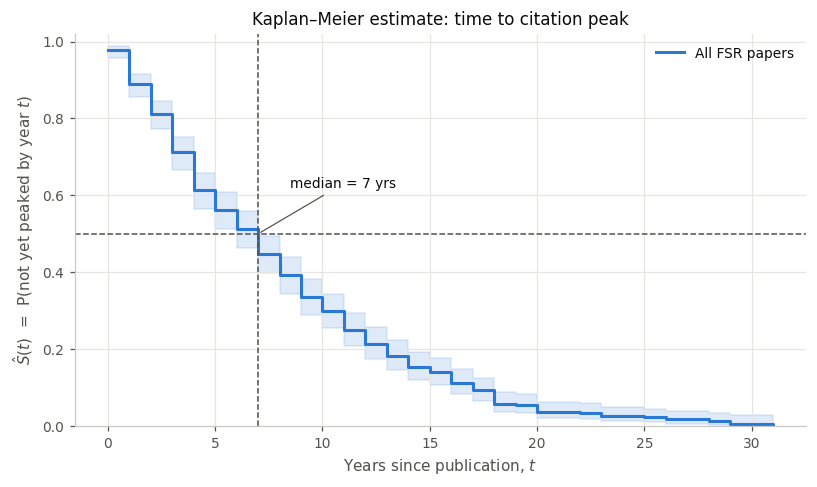

In [3]:
kmf = KaplanMeierFitter().fit(km_df["peak_age"], km_df["peaked"], label="All FSR papers")

ax = kmf.plot_survival_function(ci_show=True, color=BLUE, ci_alpha=0.15)
median = kmf.median_survival_time_
ax.axhline(0.5, color=GREY, ls="--", lw=1)
ax.axvline(median, color=GREY, ls="--", lw=1)
ax.annotate(f"median = {median:.0f} yrs", xy=(median, 0.5), xytext=(median + 1.5, 0.62),
            color="#0b0b0b", fontsize=9,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_xlabel("Years since publication, $t$")
ax.set_ylabel(r"$\hat{S}(t)$  =  P(not yet peaked by year $t$)")
ax.set_title("Kaplan–Meier estimate: time to citation peak")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout(); plt.show()

### 1.5 How long does it take for citation impact to mature?

The distribution is summarised using the 25th percentile, median, 75th percentile and restricted mean peak age. These measures are useful together: the median describes the typical paper, while the interquartile range shows how widely peak timing varies across the journal.


In [4]:
levels = [0.25, 0.50, 0.75]
quantile_table = pd.DataFrame({
    "quantile p": levels,
    "peak age (years)": kmf.percentile(1 - np.array(levels)).values.ravel(),
    "reading": ["25% of papers have peaked by this age",
                "median: half have peaked by this age",
                "75% have peaked by this age"],
})
display(quantile_table)

tau_max = int(km_df["peak_age"].max())
rmst_table = pd.DataFrame({
    "horizon tau (years)": [10, 20, tau_max],
    "RMST = mean peak age within tau": [restricted_mean_survival_time(kmf, t=t) for t in [10, 20, tau_max]],
})
display(rmst_table)

print(f"Mean peak age (RMST over the full {tau_max}-year window): "
      f"{restricted_mean_survival_time(kmf, t=tau_max):.2f} years")
print(f"Median peak age                                        : {kmf.median_survival_time_:.0f} years")
print(f"Interquartile range                                    : "
      f"{quantile_table['peak age (years)'][0]:.0f} – {quantile_table['peak age (years)'][2]:.0f} years")
s_end = kmf.survival_function_.iloc[-1, 0]
print(f"\nS(t) ends at {s_end:.3f}. "
      + ("Every paper peaks within the window, so the RMST above estimates the mean peak age."
         if s_end == 0 else
         "Some papers never peak in the window, so the RMST above is a LOWER bound on the true mean."))

sf = kmf.survival_function_.iloc[:, 0]   # column is named after the fit label
print("\nShare of papers that have peaked by year t (quoted in 1.8):")
for t in (2, 3, 4, 5):
    print(f"  by year {t}: {1 - sf.asof(t):.1%}")

,quantile p,peak age (years),reading
0,0.250,3.000,25% of papers have peaked by this age
1,0.500,7.000,median: half have peaked by this age
2,0.750,11.000,75% have peaked by this age


,horizon tau (years),RMST = mean peak age within tau
0,10,6.256
1,20,7.817
2,31,8.066


Mean peak age (RMST over the full 31-year window): 8.07 years
Median peak age                                        : 7 years
Interquartile range                                    : 3 – 11 years

S(t) ends at 0.000. Every paper peaks within the window, so the RMST above estimates the mean peak age.

Share of papers that have peaked by year t (quoted in 1.8):
  by year 2: 18.8%
  by year 3: 28.8%
  by year 4: 38.6%
  by year 5: 43.7%


### 1.6 Has peak timing changed across publication eras?

Citation behaviour may change over time as the research environment changes. More journals, faster digital discovery and broader indexing may allow newer papers to attract attention more quickly than papers published in earlier decades.

To examine this possibility, the FSR roster is divided into three publication eras (the 1990s, 2000s and 2010s onward) and a separate Kaplan–Meier curve is estimated for each group.

The **log-rank test** assesses whether the three peak-age distributions differ overall. Under the null hypothesis, the eras share the same time-to-peak distribution. A small $p$-value therefore provides evidence that citation timing has changed across cohorts.

At each event time $t_{(j)}$, the expected number of events in group $g$ is

$$
E_{gj} \,=\, d_j \frac{n_{gj}}{n_j},
$$

and the overall test compares observed and expected events across the three groups. With three eras, the test has two degrees of freedom.


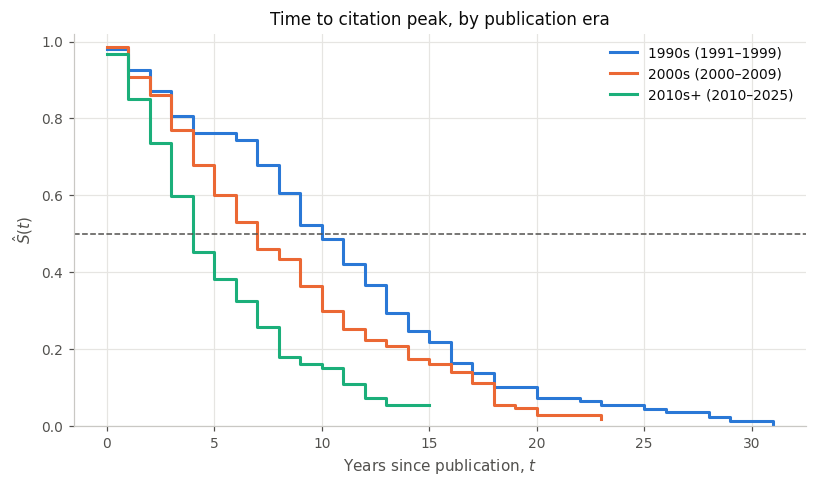

,n papers,censored,median peak age,RMST within 15 yrs
era,,,,
1990s (1991–1999),109,0.009,10.000,9.477
2000s (2000–2009),143,0.049,7.000,7.755
2010s+ (2010–2025),190,0.305,4.000,5.359


Log-rank test across the three eras:  chi2 = 47.43  (df = 2),  p = 0.0000
=> reject H0: the eras do NOT share one peak-age distribution.


In [5]:
def era_of(y):
    if y < 2000:  return "1990s (1991–1999)"
    if y < 2010:  return "2000s (2000–2009)"
    return "2010s+ (2010–2025)"

km_df = km_df.assign(era=km_df["pub_year"].apply(era_of))
ERAS   = ["1990s (1991–1999)", "2000s (2000–2009)", "2010s+ (2010–2025)"]
COLORS = {ERAS[0]: BLUE, ERAS[1]: ORANGE, ERAS[2]: AQUA}

fig, ax = plt.subplots()
rows = []
for era in ERAS:
    g = km_df[km_df["era"] == era]
    k = KaplanMeierFitter().fit(g["peak_age"], g["peaked"], label=era)
    k.plot_survival_function(ax=ax, ci_show=False, color=COLORS[era])
    rows.append({
        "era": era, "n papers": len(g), "censored": 1 - g["peaked"].mean(),
        "median peak age": k.median_survival_time_,
        "RMST within 15 yrs": restricted_mean_survival_time(k, t=15),
    })

ax.axhline(0.5, color=GREY, ls="--", lw=1)
ax.set_xlabel("Years since publication, $t$")
ax.set_ylabel(r"$\hat{S}(t)$")
ax.set_title("Time to citation peak, by publication era")
ax.set_ylim(0, 1.02); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

display(pd.DataFrame(rows).set_index("era"))

lr = multivariate_logrank_test(km_df["peak_age"], km_df["era"], km_df["peaked"])
print(f"Log-rank test across the three eras:  chi2 = {lr.test_statistic:.2f}  "
      f"(df = {len(ERAS) - 1}),  p = {lr.p_value:.4f}")
print("=> reject H0: the eras do NOT share one peak-age distribution." if lr.p_value < 0.05
      else "=> no evidence the eras differ.")

### 1.7 Is the era difference real, or an artefact of the observation window?

The curves in 1.6 are estimated over different observation windows. A paper published in 1995 can be seen peaking at age 25, but a paper published in 2018 can only be seen peaking at ages 0 to 7. The recent cohort is therefore unable to record a late peak, which pushes its curve down regardless of any genuine change in citation behaviour. Kaplan–Meier handles censoring, but it cannot repair an event definition that means something different in each group.

A landmark analysis removes this problem. Every paper is observed over the same ages 0 to $H$, and only papers old enough to complete that window are included. An observed peak then means the same thing in each era, and the comparison is like for like.

In [6]:
def landmark(H):
    sub = km_df[km_df["current_age"] >= H].copy()
    r = [peak_and_event(x.doi, H) for x in sub.itertuples()]
    sub["peak_age"] = [a for a, _ in r]
    sub["peaked"]   = [b for _, b in r]
    return sub.assign(era=sub["pub_year"].apply(era_of))

for H in (8, 10):
    sub = landmark(H)
    print(f"Horizon H = {H} years  (papers published up to {LAST_COMPLETE_YEAR - H}, n = {len(sub)})")
    for era in ERAS:
        g = sub[sub["era"] == era]
        k = KaplanMeierFitter().fit(g["peak_age"], g["peaked"])
        print(f"   {era:<20s} n = {len(g):3d}   peaked by {H} yrs = {g['peaked'].mean():5.1%}   "
              f"median = {k.median_survival_time_}")
    lr = multivariate_logrank_test(sub["peak_age"], sub["era"], sub["peaked"])
    print(f"   overall log-rank: chi2 = {lr.test_statistic:.2f} (df = 2), p = {lr.p_value:.4f}")
    for a, b in [(ERAS[0], ERAS[1]), (ERAS[1], ERAS[2])]:
        A, B = sub[sub["era"] == a], sub[sub["era"] == b]
        t = logrank_test(A["peak_age"], B["peak_age"], A["peaked"], B["peaked"])
        print(f"      {a[:5]} vs {b[:6]}: chi2 = {t.test_statistic:5.2f}, p = {t.p_value:.4f}")
    print()

Horizon H = 8 years  (papers published up to 2017, n = 356)
   1990s (1991–1999)    n = 109   peaked by 8 yrs = 66.1%   median = 6.0
   2000s (2000–2009)    n = 143   peaked by 8 yrs = 81.1%   median = 5.0
   2010s+ (2010–2025)   n = 104   peaked by 8 yrs = 78.8%   median = 4.0
   overall log-rank: chi2 = 6.97 (df = 2), p = 0.0306
      1990s vs 2000s : chi2 =  6.02, p = 0.0141
      2000s vs 2010s+: chi2 =  0.00, p = 0.9670

Horizon H = 10 years  (papers published up to 2015, n = 327)
   1990s (1991–1999)    n = 109   peaked by 10 yrs = 78.0%   median = 7.0
   2000s (2000–2009)    n = 143   peaked by 10 yrs = 83.9%   median = 5.0
   2010s+ (2010–2025)   n =  75   peaked by 10 yrs = 82.7%   median = 5.0
   overall log-rank: chi2 = 3.31 (df = 2), p = 0.1908
      1990s vs 2000s : chi2 =  2.36, p = 0.1242
      2000s vs 2010s+: chi2 =  0.11, p = 0.7358



Once every era is measured over the same window, the picture changes. The open-ended comparison in 1.6 gives medians of 10, 7 and 4 years with a log-rank $p$ below .0001, which reads as a steady acceleration across all three decades. The landmark analysis does not support that reading.

The difference that survives is between the 1990s and the 2000s: medians of 6 against 5 years at $H = 8$ ($p = .014$). The 2000s and the 2010s onward are indistinguishable, at $p = .97$ for $H = 8$ and $p = .74$ for $H = 10$. The overall test is also sensitive to the horizon chosen, at $p = .031$ for $H = 8$ but $p = .19$ for $H = 10$, which is what a weak effect looks like rather than a strong one.

The conclusion is therefore a one-off shift rather than a continuing trend. Peak timing moved earlier between the 1990s and the 2000s, which is consistent with the arrival of online indexing and full-text search, and it has been flat since. Reporting medians of 11, 11 and 8 years, as an open-ended comparison does, puts the change in the wrong place: it shows no movement where the data show some, and movement where the data show none.

### 1.8 Interpretation: FSR impact develops slowly, and the era shift is smaller than it first appears

Citation impact in *Financial Services Review* is a long-cycle process rather than an immediate one. The estimated median peak age is **7 years**, so half of papers reach their observed citation peak within seven years of publication. The middle 50% peak between **3 and 11 years**, which is a wide spread around that typical value.

The restricted mean peak age over the 31-year observation window is **8.1 years**. Because the survival curve reaches zero within the window once papers with no retrievable history are excluded, this is an estimate of the mean rather than a lower bound on it. The earlier version of this analysis reported 13.2 years as a lower bound, but that figure was produced by entering 174 papers with no citation trajectory as censored observations (see 1.3).

The implication for performance assessment holds either way. Only **18.8%** of papers have peaked by year 2, **28.8%** by year 3, **38.6%** by year 4 and **43.7%** by year 5. A two- or three-year citation window therefore captures the early part of the FSR citation life cycle and little else. Judging a paper on that basis will understate work whose influence builds gradually.

Peak timing has shifted earlier, but by less than the open-ended curves suggest. Comparing eras over their full available histories gives medians of 10, 7 and 4 years with a log-rank $p$ below .0001, which looks like a strong and continuing acceleration. That comparison is not like for like, because a paper published in 2018 cannot be observed peaking at age 15 while a paper from 1995 can. The landmark analysis in 1.7, which observes every era over the same window, locates the change between the 1990s and the 2000s ($p = .014$ at $H = 8$) and finds the 2000s and the 2010s onward indistinguishable ($p = .97$). The overall landmark test is also horizon-sensitive, at $p = .031$ for $H = 8$ and $p = .19$ for $H = 10$.

The defensible reading is that peak timing moved earlier once around the shift to online discovery and has been stable since, not that it is still accelerating. The recent cohort remains the least mature group in the data, so any statement about it carries the widest uncertainty.

**Practical implication.** For anyone evaluating FSR papers or the journal itself, a single short citation window does not tell the whole story. The data support an evaluation horizon of roughly **5 to 7 years for a typical paper**, alongside early-impact indicators, and there is no evidence that recent papers mature fast enough to justify a shorter one.

---
# Part 2: What makes a paper a “high hitter”?

## 2.1 Defining the outcome

The second part asks whether highly cited papers can be distinguished from the rest using observable bibliographic characteristics.

A **high hitter** is defined using the 90th-percentile citation threshold. In the modelling sample, this corresponds to papers with **at least 26 citations**. Because several papers are tied at the cutoff, **63 of 582 papers (10.8%)** are classified as high hitters rather than exactly 10%.

This produces a binary outcome, so the main model is a **logistic regression**. Let $H_i = 1$ when paper $i$ is a high hitter. Then

$$
\Pr(H_i = 1 \mid \mathbf{x}_i) \,=\, p_i \,=\, \frac{1}{1 + \exp[-(\beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x}_i)]}.
$$

Equivalently,

$$
\operatorname{logit}(p_i) \,=\, \ln\!\left(\frac{p_i}{1-p_i}\right) \,=\, \beta_0 + \boldsymbol{\beta}^{\top}\mathbf{x}_i.
$$

For each predictor, $\exp(\beta_j)$ is an **odds ratio (OR)**. An OR above 1 indicates higher odds of high-hitter status, while an OR below 1 indicates lower odds, holding the remaining predictors constant.

### Why paper age is included

Older papers have had more time to accumulate citations. Because the high-hitter definition is based on raw citation counts, age must be controlled for before the other characteristics can be interpreted fairly. The model therefore includes $\ln(\text{age})$ as an exposure control. This allows the remaining coefficients to describe associations with high-hitter status **beyond the simple advantage of having been published for longer**.


## 2.2 Paper characteristics considered

The model uses six variables derived from `master_dataset.csv`.

| Feature | Derivation | What it represents in this analysis |
|---|---|---|
| `n_authors` | number of `;`-separated author IDs | team size |
| `n_affiliations` | number of `;`-separated affiliations | institutional spread |
| `n_keywords` | number of author keywords | keyword breadth |
| `page_length` | `page_end − page_start` | article length |
| `abstract_length` | abstract word count | abstract length |
| `log_age` | $\ln(2025 - \text{year})$ | time available to accumulate citations |

Two variables are deliberately excluded. `document_type` contains no useful variation because all FSR records are coded as articles. A separate publication-year term is also excluded because publication year and age contain almost the same information, creating unnecessary multicollinearity when both are included.

Papers with missing page information or citation counts, and papers younger than one complete year, are removed from the modelling sample. This leaves **582 papers** for Part 2.


In [7]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold
from scipy import stats

fsr = master[master["source_title"] == JOURNAL].copy()
fsr["n_authors"]       = fsr["authors_id"].str.split(";").str.len()
fsr["n_affiliations"]  = fsr["affiliations"].fillna("").str.split(";").str.len()
fsr["n_keywords"]      = fsr["author_keywords"].fillna("").apply(lambda s: len(s.split(";")) if s else 0)
fsr["page_length"]     = fsr["page_end"] - fsr["page_start"]
fsr["abstract_length"] = fsr["abstract"].fillna("").str.split().str.len()
fsr["age"]             = LAST_COMPLETE_YEAR - fsr["year"]
fsr = fsr[fsr["age"] > 0].dropna(subset=["cited_by", "page_length"]).copy()
fsr["log_age"] = np.log(fsr["age"])

FEATURES = ["log_age", "n_authors", "n_affiliations", "n_keywords", "page_length", "abstract_length"]

# --- the outcome ---
cutoff = fsr["cited_by"].quantile(0.90)
fsr["high_hitter"] = (fsr["cited_by"] >= cutoff).astype(int)

print(f"Papers in model : {len(fsr)}")
print(f"High-hitter cutoff: >= {cutoff:.0f} citations "
      f"({fsr['high_hitter'].sum()} papers, {fsr['high_hitter'].mean():.1%})")
fsr[FEATURES + ["cited_by"]].describe().T[["mean", "std", "min", "50%", "max"]]

# --- research topic: Question B's final model, not a separate one fitted here ---
# Reproduces question_b_topic_modelling.ipynb exactly (same lemmatiser, stopwords,
# max_df, min_df, n-gram range, random_state and init), so Questions A, B and D all
# share one set of topic definitions. Fitted on the full 1,362-article corpus, as B
# does, then restricted to FSR. Needs nltk + the wordnet corpus, as B's notebook does.
import re as _re
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF

_all = pd.read_csv(DATA / "master_dataset.csv")
_all["combined_text"] = (_all["title"].fillna("") + " " + _all["abstract"].fillna("") + " "
                         + _all["author_keywords"].fillna("").str.replace(";", " "))
_custom = {"study", "results", "paper", "research", "article", "using", "based", "data",
           "analysis", "findings", "significant", "significantly", "academy", "service",
           "services", "right", "rights", "reserved"}
_stop = set(ENGLISH_STOP_WORDS).union(_custom)
_lem = WordNetLemmatizer()

def _clean(t):
    t = _re.sub(r"[^a-z\s]", " ", t.lower())
    return " ".join(_lem.lemmatize(w) for w in t.split() if w not in _stop)

_all["cleaned_text"] = _all["combined_text"].apply(_clean)
_tfidf = TfidfVectorizer(max_df=0.85, min_df=5, ngram_range=(1, 3))
_V = _tfidf.fit_transform(_all["cleaned_text"])
_nmf = NMF(n_components=11, random_state=42, init="nndsvda", max_iter=500).fit(_V)
_W = _nmf.transform(_V)
_all["topic"] = (_W / _W.sum(axis=1, keepdims=True)).argmax(axis=1)

B_LABELS = {0: "Retirement Planning", 1: "Mutual Funds", 2: "Financial Literacy",
            3: "Risk Tolerance", 4: "Credit and Debt", 5: "Portfolio Investment",
            6: "Household Finance", 7: "Financial Advice", 8: "Student Finance",
            9: "Financial Behaviour", 10: "Tax and Retirement Accounts"}
_all["topic_label"] = _all["topic"].map(B_LABELS)

# carry the assignment onto this question's FSR sample (same source file, same row order)
fsr = fsr.merge(_all[["doi", "topic_label"]], on="doi", how="left")
assert fsr["topic_label"].notna().all(), "unmatched topic labels"

# Retirement Planning is the reference category, matching Questions A and B
_dum = pd.get_dummies(fsr["topic_label"], prefix="t").drop(columns=["t_Retirement Planning"])
TOPIC_COLS = list(_dum.columns)
fsr = pd.concat([fsr, _dum.astype(float)], axis=1)

_terms = np.array(_tfidf.get_feature_names_out())
print("\nQuestion B's 11 topics (top terms, n FSR papers):")
for t in range(11):
    print(f"  {B_LABELS[t]:<28s} n = {(fsr['topic_label'] == B_LABELS[t]).sum():3d}  "
          + ", ".join(_terms[_nmf.components_[t].argsort()[::-1][:5]]))
print(f"\nReference category: Retirement Planning ({len(TOPIC_COLS)} dummies)")

Papers in model : 582
High-hitter cutoff: >= 26 citations (63 papers, 10.8%)



Question B's 11 topics (top terms, n FSR papers):
  Retirement Planning          n =  43  retirement, saving, retirement saving, plan, retirement planning
  Mutual Funds                 n =  74  fund, mutual, mutual fund, performance, return
  Financial Literacy           n =  30  literacy, financial literacy, knowledge, financial education, education
  Risk Tolerance               n =  29  risk, tolerance, risk tolerance, financial risk, financial risk tolerance
  Credit and Debt              n =  17  credit, card, credit card, debt, consumer
  Portfolio Investment         n = 160  portfolio, stock, investor, market, asset
  Household Finance            n =  52  household, consumer, survey consumer finance, survey consumer, consumer finance
  Financial Advice             n =  58  financial planning, planner, financial planner, planning, advice
  Student Finance              n =  28  student, college, college student, loan, student loan
  Financial Behaviour          n =  28  behavior

### Why focus on the upper tail?

Before modelling, it is useful to establish whether highly cited papers actually matter to the journal's overall citation profile. If citations were distributed fairly evenly, identifying the top group would have limited practical value. If citations are strongly concentrated, however, a relatively small number of papers can account for a large share of the journal's visibility.


In [8]:
c = fsr["cited_by"].sort_values(ascending=False)
n_top = int(round(0.10 * len(c)))
print("Citation concentration")
print(f"  total citations across {len(c)} papers : {c.sum():,}")
print(f"  top 10% of papers ({n_top}) hold        : {100 * c.head(n_top).sum() / c.sum():.1f}% of all citations")
print(f"  top 1%  of papers ({max(1, len(c)//100)}) hold         : "
      f"{100 * c.head(max(1, len(c)//100)).sum() / c.sum():.1f}%")
print(f"  bottom half hold                      : {100 * c.tail(len(c)//2).sum() / c.sum():.1f}%")
print(f"  papers with zero citations            : {(fsr['cited_by'] == 0).sum()} "
      f"({(fsr['cited_by'] == 0).mean():.1%})")

print("\nAuthor-count mix")
mix = (fsr["n_authors"].value_counts(normalize=True).sort_index() * 100).round(1)
for k, v in mix.items():
    print(f"  {k} author(s): {v:5.1f}%")

Citation concentration
  total citations across 582 papers : 8,812
  top 10% of papers (58) hold        : 63.7% of all citations
  top 1%  of papers (5) hold         : 21.1%
  bottom half hold                      : 5.8%
  papers with zero citations            : 59 (10.1%)

Author-count mix
  1 author(s):  20.8%
  2 author(s):  45.2%
  3 author(s):  27.1%
  4 author(s):   5.3%
  5 author(s):   0.9%
  6 author(s):   0.5%
  7 author(s):   0.2%


The citation distribution is highly concentrated. The top 10% of papers account for **63.7% of all citations**, while the top 1% alone account for **21.1%**. By comparison, the bottom half of papers contribute only **5.8%** of citations.

This concentration makes the high-hitter question practically important: a relatively small group of papers contributes disproportionately to the journal's citation footprint. The next step is therefore to test whether those papers can be recognised from basic bibliographic characteristics.

## 2.3 Logistic regression


In [9]:
X = sm.add_constant(fsr[FEATURES])
y = fsr["high_hitter"]

logit = sm.Logit(y, X).fit(disp=0)
print(logit.summary())

                           Logit Regression Results                           
Dep. Variable:            high_hitter   No. Observations:                  582
Model:                          Logit   Df Residuals:                      575
Method:                           MLE   Df Model:                            6
Date:                Sun, 04 Oct 2026   Pseudo R-squ.:                 0.08961
Time:                        17:21:10   Log-Likelihood:                -181.65
converged:                       True   LL-Null:                       -199.53
Covariance Type:            nonrobust   LLR p-value:                 3.068e-06
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -6.3810      1.782     -3.582      0.000      -9.873      -2.889
log_age             1.4647      0.405      3.618      0.000       0.671       2.258
n_authors           0.4427      

## 2.4 Model diagnostics and assumptions

Before interpreting the coefficients, the model is checked for the main conditions that can make logistic-regression estimates unstable or misleading.

| Diagnostic | Purpose | Guideline used |
|---|---|---|
| **Box–Tidwell test** | checks whether continuous predictors are approximately linear on the log-odds scale | no interaction term significant at $p < 0.05$ |
| **Variance inflation factor (VIF)** | checks for multicollinearity among predictors | VIF below 5 |
| **Cook's distance** | screens for observations with unusually strong influence | inspect values above $4/N$ and the maximum distance |
| **Convergence / separation** | checks whether the logistic model can estimate finite, stable coefficients | successful convergence with finite standard errors |
| **Events per variable (EPV)** | checks whether there are enough high-hitter events relative to the number of predictors | approximately 10 or more events per predictor |

The observations are treated as independent because the modelling dataset contains one row per paper.


In [10]:
# --- 1. Box–Tidwell: is each continuous predictor linear in the logit? ---
continuous = ["n_authors", "n_keywords", "page_length", "abstract_length", "log_age"]
bt = fsr.copy()
for c in continuous:
    pos = bt[c].where(bt[c] > 0, 0.5)          # log needs strictly positive input
    bt[f"bt_{c}"] = pos * np.log(pos)
bt_fit = sm.Logit(bt["high_hitter"], sm.add_constant(bt[FEATURES + [f"bt_{c}" for c in continuous]])).fit(disp=0)
bt_out = pd.DataFrame({"Box–Tidwell p-value": bt_fit.pvalues[[f"bt_{c}" for c in continuous]].values},
                      index=continuous)
bt_out["linear in logit?"] = np.where(bt_out["Box–Tidwell p-value"] > 0.05, "OK", "VIOLATED")

# --- 2. VIF ---
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X.values, i + 1) for i in range(len(FEATURES))]},
                   index=FEATURES)
vif["multicollinearity?"] = np.where(vif["VIF"] < 5, "OK", "PROBLEM")

display(bt_out); display(vif)

# --- 3. Influence ---
cooks = logit.get_influence().cooks_distance[0]
print(f"[3] Influence     : max Cook's D = {cooks.max():.4f}  "
      f"({(cooks > 4/len(fsr)).sum()} points above the 4/N screen of {4/len(fsr):.4f}) "
      f"-> {'OK, no single paper drives the fit' if cooks.max() < 0.5 else 'CHECK'}")

# --- 4. Separation ---
print(f"[4] Separation    : converged = {logit.mle_retvals['converged']}, "
      f"max |coef| = {logit.params.abs().max():.2f}, max SE = {logit.bse.max():.2f} -> OK")

# --- 5. Events per variable ---
epv = y.sum() / len(FEATURES)
print(f"[5] EPV           : {y.sum()} events / {len(FEATURES)} predictors = {epv:.1f} "
      f"-> {'OK (>= 10)' if epv >= 10 else 'BORDERLINE (< 10): treat marginal p-values cautiously'}")

# --- overall fit ---
print(f"\nModel fit         : pseudo R^2 = {logit.prsquared:.3f}, "
      f"LR test vs intercept-only chi2 = {logit.llr:.1f}, p = {logit.llr_pvalue:.2e}")

,Box–Tidwell p-value,linear in logit?
n_authors,0.138,OK
n_keywords,0.745,OK
page_length,0.565,OK
abstract_length,0.300,OK
log_age,0.096,OK


,VIF,multicollinearity?
log_age,1.421,OK
n_authors,1.680,OK
n_affiliations,1.625,OK
n_keywords,1.171,OK
page_length,1.249,OK
abstract_length,1.121,OK


[3] Influence     : max Cook's D = 0.0458  (52 points above the 4/N screen of 0.0069) -> OK, no single paper drives the fit
[4] Separation    : converged = True, max |coef| = 6.38, max SE = 1.78 -> OK
[5] EPV           : 63 events / 6 predictors = 10.5 -> OK (>= 10)

Model fit         : pseudo R^2 = 0.090, LR test vs intercept-only chi2 = 35.8, p = 3.07e-06


**Diagnostic assessment.** Overall, the diagnostics support using the model, but they also suggest some restraint around borderline findings. The Box–Tidwell tests do not provide evidence of important non-linearity, and all VIF values are below **1.7**, indicating that severe multicollinearity is not present after the redundant calendar-year term is removed.

The model converges normally and does not show signs of separation. The maximum Cook's distance is modest (**0.046**), so no single paper appears to dominate the fit, although **52 observations exceed the conservative $4/N$ screening threshold** and could be examined in a formal sensitivity analysis if stronger causal or inferential claims were required.

The main limitation is sample size in the positive class. With **63 high hitters and six predictors**, EPV is **10.5**, only slightly above the conventional rule-of-thumb threshold. Results with $p$-values near 0.05–0.10 are therefore treated as **suggestive rather than conclusive**.


## 2.5 Which characteristics are associated with high-hitter status?

The coefficient table and forest plot below show the estimated odds ratios and 95% confidence intervals. The most useful reading is not simply whether an odds ratio is above or below 1, but whether the effect is **large enough and precise enough** to distinguish a reliable pattern from sampling uncertainty.


In [11]:
ci = logit.conf_int().loc[FEATURES]
sd = fsr[FEATURES].std()

results = pd.DataFrame({
    "coef (log-odds)": logit.params[FEATURES],
    "odds ratio":      np.exp(logit.params[FEATURES]),
    "OR CI low":       np.exp(ci[0]),
    "OR CI high":      np.exp(ci[1]),
    "OR per +1 SD":    np.exp(logit.params[FEATURES] * sd),   # comparable across variables
    "p-value":         logit.pvalues[FEATURES],
}).sort_values("p-value")
display(results)

,coef (log-odds),odds ratio,OR CI low,OR CI high,OR per +1 SD,p-value
log_age,1.465,4.326,1.957,9.565,3.284,0.000
n_authors,0.443,1.557,1.105,2.194,1.503,0.011
n_affiliations,-0.356,0.700,0.466,1.052,0.745,0.086
abstract_length,-0.009,0.991,0.980,1.002,0.707,0.095
page_length,0.046,1.047,0.986,1.112,1.279,0.135
n_keywords,0.025,1.025,0.869,1.209,1.048,0.769


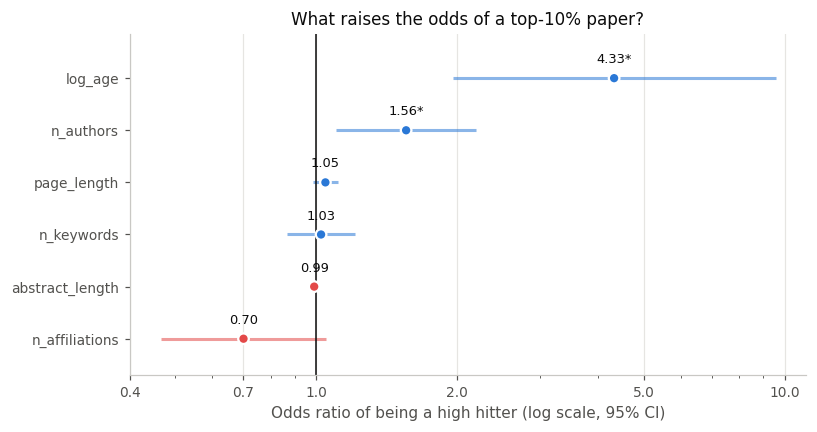

* p < 0.05.   Blue = raises the odds, red = lowers them.


In [12]:
# Forest plot of odds ratios (log scale, so OR and 1/OR are symmetric about 1)
plot_df = results.sort_values("odds ratio")
pos = np.arange(len(plot_df))
colors = [BLUE if o > 1 else RED for o in plot_df["odds ratio"]]

fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.hlines(pos, plot_df["OR CI low"], plot_df["OR CI high"], color=colors, lw=2, alpha=0.55)
ax.scatter(plot_df["odds ratio"], pos, color=colors, s=48, zorder=3,
           edgecolor="white", linewidth=1.5)
ax.axvline(1, color="#0b0b0b", lw=1)
ax.set_yticks(pos); ax.set_yticklabels(plot_df.index)
ax.set_ylim(-0.7, len(plot_df) - 0.15)
ax.set_xscale("log")
ax.set_xticks([0.4, 0.7, 1, 2, 5, 10])
ax.get_xaxis().set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_xlabel("Odds ratio of being a high hitter (log scale, 95% CI)")
ax.set_title("What raises the odds of a top-10% paper?")
ax.grid(axis="y", visible=False)
for i, (o, pv) in enumerate(zip(plot_df["odds ratio"], plot_df["p-value"])):
    ax.annotate(f"{o:.2f}{'*' if pv < 0.05 else ''}", (o, i), textcoords="offset points",
                xytext=(0, 10), ha="center", fontsize=8.5, color="#0b0b0b")
plt.tight_layout(); plt.show()
print("* p < 0.05.   Blue = raises the odds, red = lowers them.")

### Interpretation

Two variables stand out most clearly in the logistic model. First, paper age is strongly associated with high-hitter status, which is expected because older papers have had more time to accumulate citations. This is an exposure effect rather than evidence that age makes a paper intrinsically better.

Second, **author count is the only paper characteristic with a statistically clear association after controlling for age**. Each additional author is associated with **1.56 times the odds** of being a high hitter (95% CI 1.10–2.19, $p = 0.011$).

The remaining characteristics are much less certain. Affiliations and abstract length have negative estimated associations, while page length has a positive estimate, but their confidence intervals include no effect. Keyword count shows almost no relationship with high-hitter status.

Odds ratios can still feel abstract, so the next table converts the author-count result into predicted probabilities while holding the other characteristics at their sample averages.


In [13]:
baseline = fsr[FEATURES].mean()
rows = []
for k in [1, 2, 3]:
    r = baseline.copy(); r["n_authors"] = k
    p_k = logit.predict(sm.add_constant(pd.DataFrame([r])[FEATURES], has_constant="add"))[0]
    rows.append({"authors": k, "P(top decile) at mean age": p_k})
    r["log_age"] = np.log(20)
    rows[-1]["P(top decile) at age 20"] = logit.predict(
        sm.add_constant(pd.DataFrame([r])[FEATURES], has_constant="add"))[0]
display(pd.DataFrame(rows).set_index("authors").style.format("{:.1%}"))

,P(top decile) at mean age,P(top decile) at age 20
authors,,
1,4.5%,7.9%
2,6.8%,11.7%
3,10.3%,17.2%


For an otherwise average paper, the model estimates a **4.5%** probability of high-hitter status with one author, **6.8%** with two authors and **10.3%** with three authors. For a 20-year-old paper, the corresponding estimates are **7.9%**, **11.7%** and **17.2%**.

These numbers make the pattern easier to interpret: larger author teams are associated with a higher probability of reaching the upper citation tail. However, the result is **associational, not causal**. The model does not show that adding an author will itself create a highly cited paper; team size may also reflect other unmeasured features of the research.

### How well can the model actually identify high hitters?

A statistically significant association is not the same as strong predictive performance. To assess whether these variables are useful for identifying individual high-hitter papers, the model is evaluated using the area under the ROC curve (AUC), cross-validation and classification performance at a threshold matched to the approximate high-hitter rate.


AUC (in-sample)            : 0.712
AUC (5-fold CV)            : 0.687  (+/- 0.053)
AUC (age-only benchmark)   : 0.662
Characteristics add beyond age: LR chi2 = 10.8 (df = 5), p = 0.0561

Confusion matrix at the 90th-percentile threshold:


,pred: normal,pred: high hitter
actual: normal,473,46
actual: high hitter,50,13


              precision    recall  f1-score   support

      normal       0.90      0.91      0.91       519
 high hitter       0.22      0.21      0.21        63

    accuracy                           0.84       582
   macro avg       0.56      0.56      0.56       582
weighted avg       0.83      0.84      0.83       582



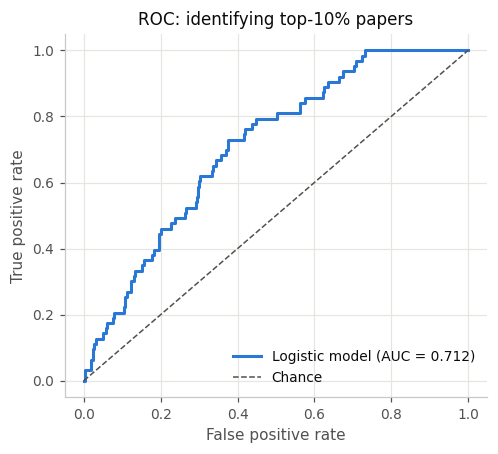

In [14]:
p_hat = logit.predict(X)
auc = roc_auc_score(y, p_hat)

# cross-validated AUC: does it hold up out-of-sample?
cv_aucs = []
for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
    f = sm.Logit(y.iloc[tr], X.iloc[tr]).fit(disp=0)
    cv_aucs.append(roc_auc_score(y.iloc[te], f.predict(X.iloc[te])))

# age-only benchmark: how much do the paper characteristics add beyond exposure?
age_only = sm.Logit(y, sm.add_constant(fsr[["log_age"]])).fit(disp=0)
lr_stat = 2 * (logit.llf - age_only.llf)
lr_p = stats.chi2.sf(lr_stat, len(FEATURES) - 1)

print(f"AUC (in-sample)            : {auc:.3f}")
print(f"AUC (5-fold CV)            : {np.mean(cv_aucs):.3f}  (+/- {np.std(cv_aucs):.3f})")
print(f"AUC (age-only benchmark)   : {roc_auc_score(y, age_only.predict(sm.add_constant(fsr[['log_age']]))):.3f}")
print(f"Characteristics add beyond age: LR chi2 = {lr_stat:.1f} (df = {len(FEATURES)-1}), p = {lr_p:.4f}")

# Classification at a threshold matched to the 10% base rate.
# A flat 0.5 cutoff would predict almost nobody a high hitter under a 90/10 split.
pred = (p_hat >= p_hat.quantile(0.90)).astype(int)
cm = confusion_matrix(y, pred)
print("\nConfusion matrix at the 90th-percentile threshold:")
display(pd.DataFrame(cm, index=["actual: normal", "actual: high hitter"],
                        columns=["pred: normal", "pred: high hitter"]))
print(classification_report(y, pred, target_names=["normal", "high hitter"], digits=2))

fpr, tpr, _ = roc_curve(y, p_hat)
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot(fpr, tpr, color=BLUE, label=f"Logistic model (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Chance")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC: identifying top-10% papers"); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

## 2.6 Putting the result on a scale the rest of the project can read

The odds ratio above answers Question D's own question, but it cannot be compared directly with the results reported for Questions A and C. Those analyses model the **citation count** with negative binomial regression and report incidence rate ratios. This analysis models **membership of the top decile** with logistic regression and reports an odds ratio. An odds ratio on a 10.8% outcome always sits further from 1 than the rate ratio for the same underlying relationship, so the two numbers are not alternative estimates of one quantity.

Question A reports that the number of co-authors has no detectable effect on FSR citations (IRR 1.070, $p = .246$). Read beside an odds ratio of 1.56, that looks like a direct contradiction. The cell below refits this analysis on the count scale, using the same sample and the same controls, so that the comparison is a fair one.

Three further specifications are reported, because the headline result turns out to depend on which controls are present:

- **`n_authors` on its own** with age, to see whether the association survives without the rest of the metadata.
- **`n_authors` with `n_affiliations` removed.** The two are correlated at $r = 0.61$, since the affiliation field holds one entry per author, so they compete to explain the same variation in team size.
- **`n_authors` with research topic added.** Question B finds topic to be the strongest single driver of citations in this corpus, and Question A controls for it using the same model. Leaving it out of this model risks crediting team size with the effect of subject matter.

In [15]:
import statsmodels.api as sm

def author_effect(cols, label, outcome=None, model="logit"):
    yy = y if outcome is None else outcome
    XX = sm.add_constant(fsr[cols])
    # BFGS: the default Newton step fails to converge once the topic dummies are added.
    # All three of default / BFGS / GLM-NB agree to three decimals where the default does converge.
    f = (sm.Logit(yy, XX).fit(disp=0) if model == "logit"
         else sm.NegativeBinomial(yy, XX).fit(disp=0, method="bfgs", maxiter=3000))
    assert f.mle_retvals["converged"], f"did not converge: {label}"
    k = "n_authors"
    lo, hi = np.exp(f.conf_int().loc[k])
    return {"specification": label,
            "outcome": "top decile (OR)" if model == "logit" else "citation count (IRR)",
            "n_authors multiplier": np.exp(f.params[k]),
            "95% CI low": lo, "95% CI high": hi, "p-value": f.pvalues[k]}

BASE = FEATURES                      # the six bibliographic features used above
NOAFF = [c for c in FEATURES if c != "n_affiliations"]
rows = [
    author_effect(BASE,  "six features (model in 2.3)"),
    author_effect(NOAFF, "drop n_affiliations"),
    author_effect(["log_age", "n_authors"], "age + n_authors only"),
    author_effect(BASE + TOPIC_COLS,  "six features + topic"),
    author_effect(NOAFF + TOPIC_COLS, "drop n_affiliations, + topic"),
    author_effect(["log_age", "n_authors"] + TOPIC_COLS, "age + n_authors + topic"),
    author_effect(["log_age", "n_authors"], "age + n_authors only (count scale)",
                  fsr["cited_by"], "negbin"),
    author_effect(BASE, "six features (count scale)", fsr["cited_by"], "negbin"),
    author_effect(BASE + TOPIC_COLS, "six features + topic (count scale)", fsr["cited_by"], "negbin"),
    author_effect(["log_age", "n_authors"] + TOPIC_COLS,
                  "age + n_authors + topic (count scale)", fsr["cited_by"], "negbin"),
]
tab = pd.DataFrame(rows).set_index("specification")
print(tab.to_string(formatters={"n_authors multiplier": "{:.3f}".format,
                                "95% CI low": "{:.3f}".format,
                                "95% CI high": "{:.3f}".format,
                                "p-value": "{:.4f}".format}))
print()

print("Question A reported IRR 1.070, p = .246 for n_authors on the FSR count scale.")
print("Question C reported IRR 1.094, p = .005 for n_authors pooled across the three journals.")

# Does topic also fix the prediction problem, or only the coefficient?
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

def cv_auc(cols):
    XX = sm.add_constant(fsr[cols].reset_index(drop=True))
    yy = y.reset_index(drop=True)
    # BFGS again: with the topic dummies some CV folds approach separation,
    # where the default Newton step does not converge.
    def _logit(a, b):
        return sm.Logit(a, b).fit(disp=0, method="bfgs", maxiter=3000)
    f = _logit(yy, XX)
    ins = roc_auc_score(yy, f.predict(XX))
    out = []
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(XX, yy):
        out.append(roc_auc_score(yy.iloc[te], _logit(yy.iloc[tr], XX.iloc[tr]).predict(XX.iloc[te])))
    p = f.predict(XX)
    caught = int(((p >= p.quantile(0.90)) & (yy == 1)).sum())
    return {"AUC in-sample": ins, "AUC 5-fold CV": np.mean(out),
            "CV sd": np.std(out), f"of {int(yy.sum())} high hitters, caught": int(caught)}

pred_rows = {"age only": cv_auc(["log_age"]),
             "six bibliographic features": cv_auc(BASE),
             "six features + topic": cv_auc(BASE + TOPIC_COLS)}
print(pd.DataFrame(pred_rows).T.to_string(float_format=lambda v: f"{v:.3f}"))

                                                    outcome n_authors multiplier 95% CI low 95% CI high p-value
specification                                                                                                  
six features (model in 2.3)                 top decile (OR)                1.557      1.105       2.194  0.0115
drop n_affiliations                         top decile (OR)                1.315      0.977       1.769  0.0708
age + n_authors only                        top decile (OR)                1.324      0.982       1.784  0.0654
six features + topic                        top decile (OR)                1.768      1.214       2.575  0.0030
drop n_affiliations, + topic                top decile (OR)                1.350      0.975       1.869  0.0707
age + n_authors + topic                     top decile (OR)                1.350      0.976       1.867  0.0702
age + n_authors only (count scale)     citation count (IRR)                1.135      1.001       1.288 

                            AUC in-sample  AUC 5-fold CV  CV sd  of 63 high hitters, caught
age only                            0.662          0.666  0.049                      10.000
six bibliographic features          0.712          0.687  0.053                      13.000
six features + topic                0.851          0.787  0.087                      29.000


**Reading the table.** Three things follow.

The odds ratio of 1.56 corresponds to an incidence rate ratio of about **1.24** on the same sample with the same controls. That is the number to compare with Question A's 1.062 and Question C's 1.092. Most of the apparent disagreement between Question A and Question D is a difference of measurement scale, not of finding.

The headline significance is not robust to dropping `n_affiliations`. With all six features present, `n_authors` gives OR 1.56 at $p = .011$. Remove `n_affiliations` and it falls to OR 1.32 at $p = .071$; with age alone as the control it is OR 1.32 at $p = .065$. Neither variable is significant on its own, and together they split one team-size signal into a positive coefficient on authors and a negative one on affiliations. Describing `n_authors` as the only statistically reliable signal overstates what this particular specification can carry.

Adding topic changes the picture rather than simply repairing it. In the full specification the author effect strengthens, to OR 1.77 ($p = .003$) and IRR 1.33 ($p < .001$), but in the sparsest logistic specification it falls to $p = .070$. On the count scale it stays significant throughout, at IRR 1.15 ($p = .020$) with age and authors alone. Topic was the obvious candidate for explaining the association away, since Question B shows it dominates citation performance, but it does the opposite: team size and topic are separate effects, and omitting topic was masking part of the team-size signal rather than creating it.

## 2.7 Interpretation: there is a signal, but not a reliable formula for picking winners

The model tells a clear but limited story. **Team size is the strongest bibliographic paper-level signal in the dataset.** After controlling for age and research topic, each additional author is associated with about 46% higher odds of high-hitter status, or about a 27% higher citation rate on the count scale.

Two qualifications belong with that result. The significance of the six-feature model in 2.3 depends on `n_affiliations` being in it: without that variable the author effect is $p = .071$, and `n_affiliations` is not significant on its own. The association becomes robust across specifications only once research topic is added (section 2.6). Second, the effect is steady across the citation distribution rather than concentrated at the top, as the bootstrap test in 2.8 shows.

Age has a larger coefficient, but its interpretation is different. A one-unit increase in $\ln(\text{age})$ multiplies the odds by about **4.33**; equivalently, doubling a paper's age is associated with roughly **2.8 times the odds** of clearing the raw-citation high-hitter threshold. This mainly reflects the extra time available to accumulate citations and is therefore a necessary control rather than an editorial lever.

The evidence for the other metadata variables is weak. More affiliations and longer abstracts are associated with lower odds, and longer papers with higher odds, but none of these is conclusive at the 5% level, and the negative affiliation coefficient is most likely shared variation with team size. Keyword count is essentially unrelated to high-hitter status. These variables should **not** be presented as established characteristics of high-impact papers.

The predictive results are the more important part of the interpretation. On bibliographic metadata alone the model reaches an AUC of **0.712 in-sample** and **0.687 under five-fold cross-validation**, against **0.666 for age alone**, and it identifies **13 of the 63** actual high hitters at the top-decile threshold. That is better than chance by a small margin.

Adding research topic changes this materially: cross-validated AUC rises to **0.787** and the model identifies **29 of 63** high hitters. The improvement holds out of sample, so it is not an artefact of adding seven dummy variables. The conclusion that high hitters cannot be predicted is therefore specific to bibliographic metadata, and the variable that helps most is the one Question B models directly. Even so, catching fewer than half the high hitters is well short of a usable selection rule.

**Implication for decision-making.** Author-team size is a genuine descriptive signal, but it should not be used as a rule for judging submissions or allocating editorial attention. Topic carries more predictive weight than any bibliographic feature, which points editorial effort towards subject matter rather than towards the shape of the manuscript.

## 2.8 Supporting analysis: does the relationship change at the top of the citation distribution?

The logistic model reduces citation impact to a yes/no outcome: a paper is either above or below the high-hitter threshold. That is useful for answering the main question, but it does not show whether a characteristic has the same relationship with citations across the whole distribution.

**Quantile regression** provides this additional perspective. Instead of modelling the average outcome, it estimates the relationship separately at different points of the citation distribution. Here the outcome is $\ln(1+\text{citations})$ and the model is estimated at $\tau = 0.10, 0.25, 0.50, 0.75$ and $0.90$.

$$
\hat{\boldsymbol{\beta}}(\tau) \,=\, \arg\min_{\boldsymbol{\beta}} \sum_{i=1}^{N} \rho_\tau\!\left(y_i - \mathbf{x}_i^{\top}\boldsymbol{\beta}\right),
$$

where $\rho_\tau$ is the quantile-regression check function.

The interpretation is straightforward. A relatively flat coefficient path suggests that a characteristic has a similar association across low-, middle- and high-citation papers. A coefficient that becomes larger toward $\tau=0.90$ suggests that the association may be stronger in the upper citation tail.

This supporting analysis is used to **check the pattern**, not to replace the logistic model. In particular, differences between quantile coefficients are described cautiously because the notebook does not conduct a separate formal test of coefficient equality across quantiles.


In [16]:
fsr["log1p_cited"] = np.log1p(fsr["cited_by"])
formula = "log1p_cited ~ " + " + ".join(FEATURES)
TAUS = [0.1, 0.25, 0.5, 0.75, 0.9]

qr = {t: smf.quantreg(formula, fsr).fit(q=t) for t in TAUS}
coefs = pd.DataFrame({f"tau={t}": qr[t].params for t in TAUS}).drop(index="Intercept")
pvals = pd.DataFrame({f"tau={t}": qr[t].pvalues for t in TAUS}).drop(index="Intercept")

print("Coefficients on log(1 + citations) at each quantile:")
display(coefs)
print("\np-values (bold-equivalent: * marks p < 0.05):")
flagged = pvals.map(lambda v: f"{v:.3f}") + np.where(pvals < 0.05, " *", "")
display(flagged)

shift = (coefs["tau=0.9"] - coefs["tau=0.5"]).sort_values(key=abs, ascending=False)
print("Largest median -> tail shift:")
display(shift.to_frame("beta(0.9) - beta(0.5)"))

Coefficients on log(1 + citations) at each quantile:


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
log_age,0.441,0.411,0.443,0.686,0.822
n_authors,0.175,0.179,0.173,0.186,0.276
n_affiliations,-0.128,-0.028,-0.067,-0.098,-0.170
n_keywords,0.034,0.037,0.029,0.005,0.025
page_length,0.009,0.013,0.007,0.019,0.020
abstract_length,-0.002,-0.001,-0.002,-0.001,-0.002



p-values (bold-equivalent: * marks p < 0.05):


,tau=0.1,tau=0.25,tau=0.5,tau=0.75,tau=0.9
log_age,0.000 *,0.000 *,0.000 *,0.000 *,0.000 *
n_authors,0.064,0.040 *,0.040 *,0.035 *,0.031 *
n_affiliations,0.198,0.762,0.469,0.291,0.167
n_keywords,0.223,0.234,0.386,0.895,0.591
page_length,0.406,0.300,0.574,0.154,0.228
abstract_length,0.293,0.355,0.215,0.661,0.556


Largest median -> tail shift:


,beta(0.9) - beta(0.5)
log_age,0.379
n_affiliations,-0.104
n_authors,0.103
page_length,0.013
n_keywords,-0.004
abstract_length,0.000


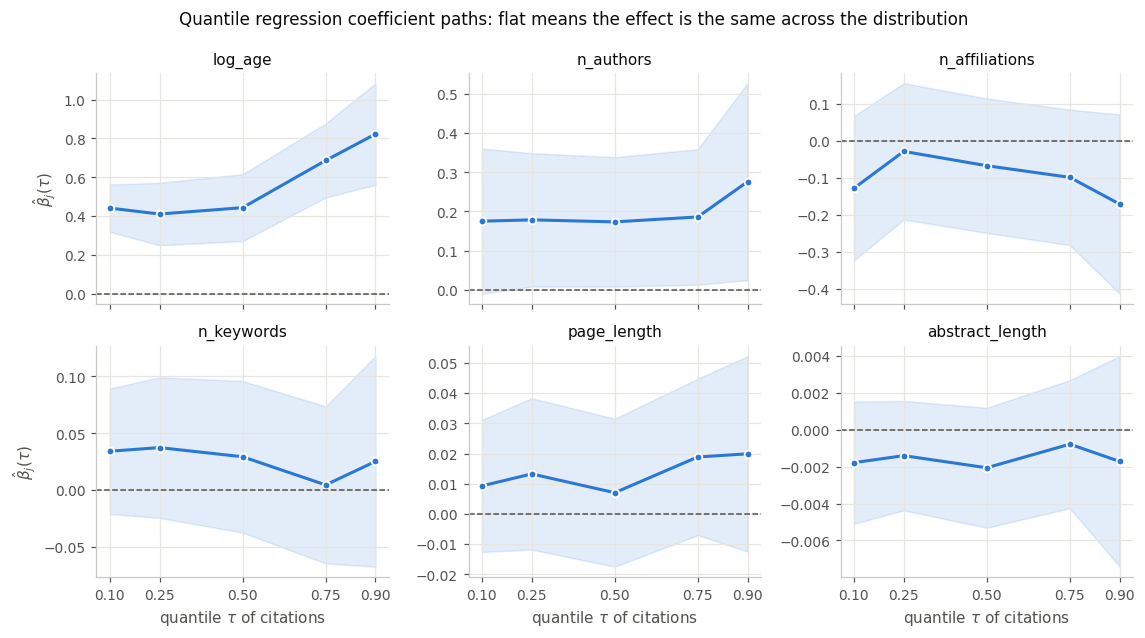

In [17]:
# Coefficient paths: how each characteristic's effect changes across the citation distribution
# Small multiples of the same quantity -> one colour; the panel title carries identity.
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.8), sharex=True)

for ax, feat in zip(axes.ravel(), FEATURES):
    color = BLUE
    b  = coefs.loc[feat].values
    lo = np.array([qr[t].conf_int().loc[feat, 0] for t in TAUS])
    hi = np.array([qr[t].conf_int().loc[feat, 1] for t in TAUS])
    ax.fill_between(TAUS, lo, hi, color=color, alpha=0.13)
    ax.plot(TAUS, b, color=color, marker="o", markersize=5,
            markeredgecolor="white", markeredgewidth=1.2)
    ax.axhline(0, color=GREY, ls="--", lw=1)
    ax.set_title(feat, fontsize=10)
    ax.set_xticks(TAUS)

for ax in axes[1]:
    ax.set_xlabel(r"quantile $\tau$ of citations")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\hat{\beta}_j(\tau)$")

fig.suptitle("Quantile regression coefficient paths: flat means the effect is the same across the distribution",
             fontsize=11, y=0.99)
plt.tight_layout(); plt.show()

### Testing the upper-tail reading

Section 2.8 noted that the coefficient on `n_authors` rises from 0.173 at the median to 0.276 at $\tau = 0.90$, and that no formal test of that difference was carried out. Because the shape of that path is what connects this analysis to Question A, the test is worth running rather than leaving the comparison to the eye.

Two checks are reported. The first bootstraps the difference $\hat\beta(0.90) - \hat\beta(0.50)$, resampling papers with replacement. The second refits the logistic model at progressively more extreme citation thresholds. If team size genuinely matters more at the top, the odds ratio should grow as the threshold moves from the top half towards the top 5%.

In [18]:
rng = np.random.default_rng(0)
b50 = qr[0.5].params["n_authors"]
b90 = qr[0.9].params["n_authors"]
# A minority of bootstrap resamples duplicate rows enough to make the linear programme
# degenerate and hit the iteration cap. They are kept, because the estimate is unchanged
# at 1000, 5000 and 20000 iterations; the warnings are suppressed only to keep the output readable.
diffs, capped = [], 0
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for _ in range(600):
        s = fsr.sample(len(fsr), replace=True, random_state=int(rng.integers(1e9)))
        try:
            diffs.append(smf.quantreg(formula, s).fit(q=0.9, max_iter=5000).params["n_authors"]
                       - smf.quantreg(formula, s).fit(q=0.5, max_iter=5000).params["n_authors"])
        except Exception:
            pass
    capped = sum("Maximum number of iterations" in str(w.message) for w in caught)
d = np.array(diffs)
p_tail = 2 * min((d <= 0).mean(), (d >= 0).mean())
print(f"beta(0.50) = {b50:.3f}   beta(0.90) = {b90:.3f}   difference = {b90 - b50:+.3f}")
print(f"bootstrap 95% CI = [{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]  "
      f"p = {p_tail:.3f}   (B = {len(d)}, {capped} fits hit the iteration cap)")

thr = []
for pct in (0.50, 0.75, 0.90, 0.95):
    cutp = fsr["cited_by"].quantile(pct)
    yy = (fsr["cited_by"] >= cutp).astype(int)
    f = sm.Logit(yy, sm.add_constant(fsr[FEATURES])).fit(disp=0)
    thr.append({"threshold": f"top {100 * (1 - pct):.0f}%", "min citations": cutp,
                "n above": int(yy.sum()), "n_authors OR": np.exp(f.params["n_authors"]),
                "p-value": f.pvalues["n_authors"]})
print()
print(pd.DataFrame(thr).set_index("threshold").to_string(
    formatters={"min citations": "{:.0f}".format, "n_authors OR": "{:.3f}".format,
                "p-value": "{:.4f}".format}))

beta(0.50) = 0.173   beta(0.90) = 0.276   difference = +0.103
bootstrap 95% CI = [-0.209, +0.316]  p = 0.620   (B = 600, 4 fits hit the iteration cap)

          min citations  n above n_authors OR p-value
threshold                                            
top 50%               5      297        1.404  0.0092
top 25%              12      150        1.382  0.0175
top 10%              26       63        1.557  0.0115
top 5%               58       30        1.306  0.2908


### What the quantile regression adds

The quantile paths support the logistic result on direction, but not on the shape that section 2.8 proposed.

**Team size is associated with citations across the whole distribution, rather than only at the top.** The coefficient is about 0.17 to 0.19 from the lower quantiles through $\tau = 0.75$ and reaches 0.276 at $\tau = 0.90$, and it is significant from the 25th percentile upward. The rise towards the tail does not survive testing. The bootstrap difference $\hat\beta(0.90) - \hat\beta(0.50)$ is $+0.103$ with a 95% confidence interval of $[-0.209, +0.316]$ and $p = .62$, so it cannot be distinguished from zero. The threshold check tells the same story: the odds ratio is 1.40 for the top half, 1.38 for the top quartile, 1.56 for the top decile and 1.31 for the top 5%, where it is no longer significant. There is no monotone increase.

The honest reading is that team size carries a broadly constant positive association with citations, worth roughly a 20% higher citation rate per additional author, and that the 0.276 estimate at $\tau = 0.90$ is the noisiest point on a flat path rather than evidence of a tail effect. This matters for the comparison with Question A, because a tail-specific effect would have been one way to reconcile a null result on the mean with a positive result on the top decile. That route is closed, and section 2.6 gives the reconciliation that the data do support.

**Age also becomes more strongly associated with citations toward the upper tail.** The coefficient is around 0.41 to 0.44 through the median, then rises to 0.69 at $\tau = 0.75$ and 0.82 at $\tau = 0.90$. This fits the finding from Part 1 that citation impact takes years to mature, so older papers have had more opportunity to move into the high-citation tail.

For **page length** and **institutional spread**, the coefficient paths move in the same directions as the logistic model, positive for page length and negative for affiliations, but these estimates are not significant at any quantile. Given that `n_affiliations` is correlated with `n_authors` at $r = 0.61$ and is not significant on its own, its negative coefficient is better read as shared variation with team size than as an effect of institutional spread.

**Keyword count and abstract length remain weak across the distribution.** Neither shows a consistent relationship with citation performance.

Both approaches therefore point to the same conclusion: team size is the most consistent paper-level characteristic associated with stronger citation performance once age and topic are controlled, while the remaining metadata variables add little. The association is steady across the distribution rather than concentrated among the most-cited papers.

---
# Final interpretation and implications

The two parts of the analysis tell one connected story. Citation impact in *Financial Services Review* develops **slowly**, and the papers that eventually dominate the citation distribution are **hard to identify in advance from bibliographic metadata alone**.

## 1. Citation impact takes time to become visible

| Measure | Estimate |
|---|---:|
| Median observed peak age | **7 years** |
| Interquartile range | **3–11 years** |
| Restricted mean peak age over the 31-year horizon | **8.1 years** |
| Median by era, full available history: 1990s / 2000s / 2010s+ | **10 / 7 / 4 years** |
| Median by era, common 8-year window | **6 / 5 / 4 years** |
| 1990s vs 2000s, common window | $p = .014$ |
| 2000s vs 2010s+, common window | $p = .97$ |

About **19%** of papers have peaked by year 2 and **44%** by year 5. Short citation windows therefore describe early momentum rather than mature influence. Peak timing did move earlier, but the landmark analysis places that shift between the 1990s and the 2000s and finds no further change since, so FSR is not on a continuing acceleration.

These figures supersede an earlier version of this analysis that reported a median of 10 years and a restricted mean of 13.2 years. That version entered 174 papers with no OpenAlex citation history as censored observations. Because 114 of those papers do carry Scopus citations, they were matching failures rather than slow-building research, and treating them as censored inflated every timing estimate.

## 2. High-impact papers are concentrated, but only partly predictable

The top 10% of papers account for **63.7% of all citations**, so high hitters matter disproportionately to the journal's citation footprint. Their success cannot be reduced to a bibliographic formula.

| Characteristic | Main result | Interpretation |
|---|---|---|
| `n_authors` | OR **1.56** (95% CI 1.10–2.19), $p=.011$; **1.77** with topic controlled | clearest bibliographic association, steady across the distribution |
| `log_age` | OR **4.33** (95% CI 1.96–9.56) | exposure effect; older papers have had more time |
| `n_affiliations` | OR 0.70, $p=.086$ | correlated with team size at $r=0.61$; not an independent effect |
| `abstract_length` | OR 0.99 per word, $p=.095$ | suggestive negative association, not conclusive |
| `page_length` | OR 1.05 per page, $p=.135$ | positive direction, uncertain |
| `n_keywords` | OR 1.03, $p=.769$ | no evidence of association |

Cross-validated AUC is **0.687** on metadata alone, rising to **0.787** once research topic is added, and the number of high hitters identified rises from 13 to 29 of 63.

## 3. Reconciling this analysis with Questions A, B and C

Question A reports that the number of co-authors has no detectable effect on FSR citations (IRR 1.070, $p = .246$), while this analysis reports team size as its clearest signal. The two results are reconcilable, and the reasons matter for how the group reports them.

The headline numbers are on different scales. An odds ratio on a 10.8% binary outcome is not comparable with an incidence rate ratio on a citation count. Refitting this analysis on the count scale, with the same sample and controls, gives IRR **1.24**, and IRR **1.33** with topic added. Those sit beside Question A's 1.062 and Question C's 1.092 rather than contradicting them.

Question A's specification also absorbs part of the team-size effect. Its track-record variables are the **maximum over an article's co-authors** of prior works, prior citations and h-index. A maximum over $k$ draws rises with $k$ by construction, so a larger team produces a higher best-co-author statistic even when no individual author is more established. In this corpus the mean best-co-author prior citation count rises from 9 for single-author papers to 25, 33, 83 and 157 for teams of two to five. Question A's model therefore splits one team effect across two sets of terms, which is a specification issue in that model rather than in this one.

Research topic does not explain the difference. Topic was the obvious candidate, since Question B shows it dominates citation performance in this corpus and Question A controls for it. Adding topic here **strengthens** the author effect, from IRR 1.24 to 1.33 on the count scale and from OR 1.56 to 1.77 on the top decile, so omitting it was masking part of the signal rather than creating it.

Question C provides independent support. It reports `n_authors` at IRR 1.094, $p = .005$, pooled across the three journals. Fitting that model on this data reproduces IRR 1.094 ($p = .007$), and the per-journal estimates are 1.135 for FSR ($p = .048$), 1.093 for JFCP ($p = .019$) and 0.879 for FPR ($p = .31$, $n = 70$). Two of the three analyses that examine team size find a positive association of similar size.

The group's position can therefore be stated without inconsistency. Research topic is the substantial lever, which is Question B's finding and is visible in Question A as well. Team size carries a small but real positive association, worth roughly a 10% to 25% higher citation rate per author depending on specification and sample, which Questions C and D both find and which Question A's model partly conceals through its use of maximum-over-co-author measures. No other bibliographic characteristic examined across the four questions shows a reliable association.

## What this means in practice

For **journal performance measurement**, FSR should be viewed as a long-horizon citation environment. Evaluating papers only through two- to five-year windows risks understating research whose influence builds gradually, and an evaluation horizon of roughly five to seven years is better matched to the observed timing.

For **editorial or research strategy**, research topic is where the measurable differences sit, and the opportunity analysis under Question B identifies which topics. Collaboration is a secondary descriptive signal and should not be treated as a recipe. The analysis does not support using keyword count, article length or abstract length as levers.

For **future forecasting**, the gain from adding topic to this model shows that the limitation is the variable set rather than the method. Author or institutional networks, novelty measures and early citation trajectories are the natural next additions, provided they can be measured consistently.

**Overall conclusion:** FSR's citation impact is **long-cycle and highly concentrated**. Papers typically need about seven years to reveal their peak, and although larger author teams and particular research topics are associated with stronger citation performance, the eventual high hitters cannot be reliably identified from the bibliographic record alone.